In [12]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect()
cars = con.read_parquet("../data/processed/clean.parquet")

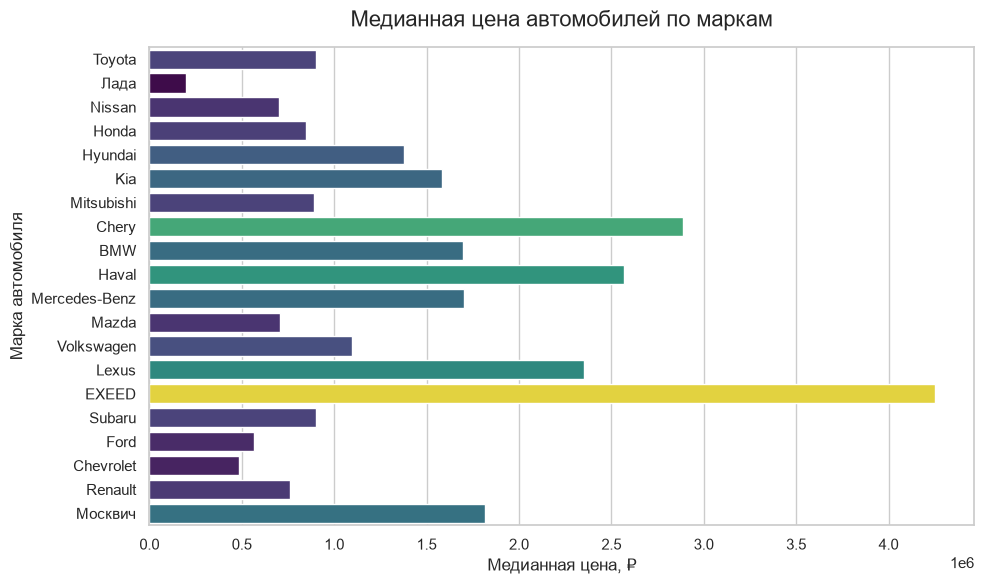

In [13]:
df = con.sql("""
    SELECT
        brand,
        count(*) AS ads_count,
        median(price) AS median_price
    FROM cars
    GROUP BY brand
    ORDER BY ads_count DESC
""").df()

sns.set_theme(style="whitegrid", palette="viridis")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df.head(20),
    x="median_price",
    y="brand",
    hue="median_price",
    palette="viridis",
    legend=False
)

plt.title("Медианная цена автомобилей по маркам", fontsize=16, pad=15)
plt.xlabel("Медианная цена, ₽", fontsize=12)
plt.ylabel("Марка автомобиля", fontsize=12)

plt.tight_layout()
plt.show()

In [17]:
df = con.sql("""
    SELECT * EXCLUDE (description, link)
    FROM cars
    LIMIT 10
""").show()
# df.to_csv('test.csv')

┌─────────┬─────────┬───────────┬─────────────┬──────────┬───────┬─────────┬──────────────┬───────┬────────┬─────────────────────┬─────────────────┬─────────────────────┬─────────┬──────────────────┬──────────────┬───────────────┬───────────────────────────────┬──────────────────┬───────────┐
│  brand  │  name   │ bodyType  │    color    │ fuelType │ year  │ mileage │ transmission │ power │ price  │        date         │    location     │     parse_date      │ car_age │ mileage_per_year │ brand_origin │ price_segment │            region             │ federal_district │ is_dealer │
│ varchar │ varchar │  varchar  │   varchar   │ varchar  │ int16 │  int32  │   varchar    │ int16 │ int64  │      timestamp      │     varchar     │      timestamp      │  int16  │      double      │   varchar    │    varchar    │            varchar            │     varchar      │  boolean  │
├─────────┼─────────┼───────────┼─────────────┼──────────┼───────┼─────────┼──────────────┼───────┼────────┼──────────